In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [2]:
#load the dataset

df = pd.read_csv("food-texture.csv")

print("First 5 rows:")
print(df.head())

print("\n Dataset shape:")
print(df.shape)

print("\n Column names:")
print(df.columns.tolist())


First 5 rows:
  Unnamed: 0   Oil  Density  Crispy  Fracture  Hardness
0       B110  16.5     2955      10        23        97
1       B136  17.7     2660      14         9       139
2       B171  16.2     2870      12        17       143
3       B192  16.7     2920      10        31        95
4       B225  16.3     2975      11        26       143

 Dataset shape:
(50, 6)

 Column names:
['Unnamed: 0', 'Oil', 'Density', 'Crispy', 'Fracture', 'Hardness']


In [3]:
#EDA

print("\n Dataset information")
df.info()

print("\n Descriptive statistics")
print(df.describe())

print("\n Missing values")
print(df.isnull().sum())

print("\n Duplicate rows:")
print(df.duplicated().sum())



 Dataset information
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  50 non-null     str    
 1   Oil         50 non-null     float64
 2   Density     50 non-null     int64  
 3   Crispy      50 non-null     int64  
 4   Fracture    50 non-null     int64  
 5   Hardness    50 non-null     int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 2.5 KB

 Descriptive statistics
             Oil     Density     Crispy   Fracture    Hardness
count  50.000000    50.00000  50.000000  50.000000   50.000000
mean   17.202000  2857.60000  11.520000  20.860000  128.180000
std     1.592007   124.49998   1.775571   5.466073   31.127578
min    13.700000  2570.00000   7.000000   9.000000   63.000000
25%    16.300000  2772.50000  10.000000  17.000000  107.250000
50%    16.900000  2867.50000  12.000000  21.000000  126.000000
75%    18.100000  2945.00000  13.00

In [7]:
#select input features and target

features = ["Oil","Density","Fracture","Hardness"]

X = df[features]
y = df["Crispy"]

print("\n Input features")
print(X.head())

print("\n Target variable")
print(y.head())

print("\n Number of input features:", len(features))


 Input features
    Oil  Density  Fracture  Hardness
0  16.5     2955        23        97
1  17.7     2660         9       139
2  16.2     2870        17       143
3  16.7     2920        31        95
4  16.3     2975        26       143

 Target variable
0    10
1    14
2    12
3    10
4    11
Name: Crispy, dtype: int64

 Number of input features: 4


In [8]:
print("\n Data types")
print(df.dtypes)


 Data types
Unnamed: 0        str
Oil           float64
Density         int64
Crispy          int64
Fracture        int64
Hardness        int64
dtype: object


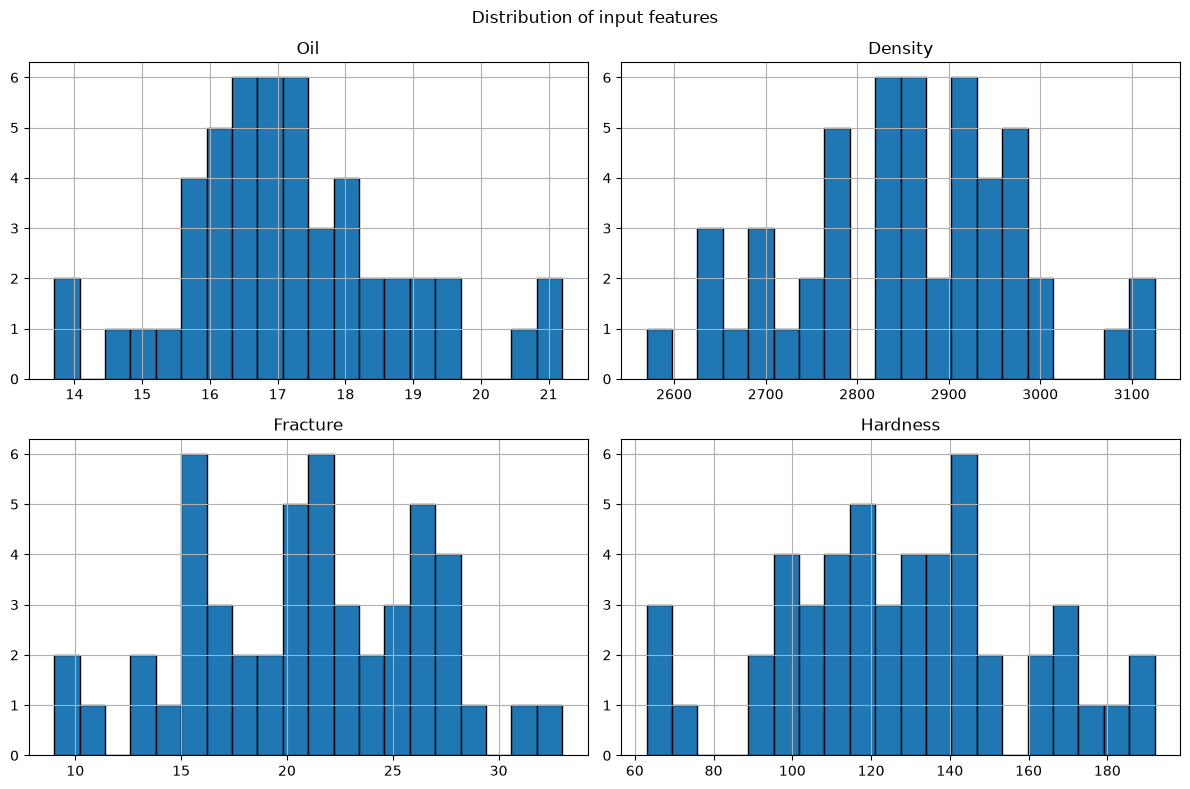

In [9]:
#Histograms of all input features

X.hist(figsize=(12,8), bins=20, edgecolor="black")

plt.suptitle("Distribution of input features")
plt.tight_layout()
plt.show()

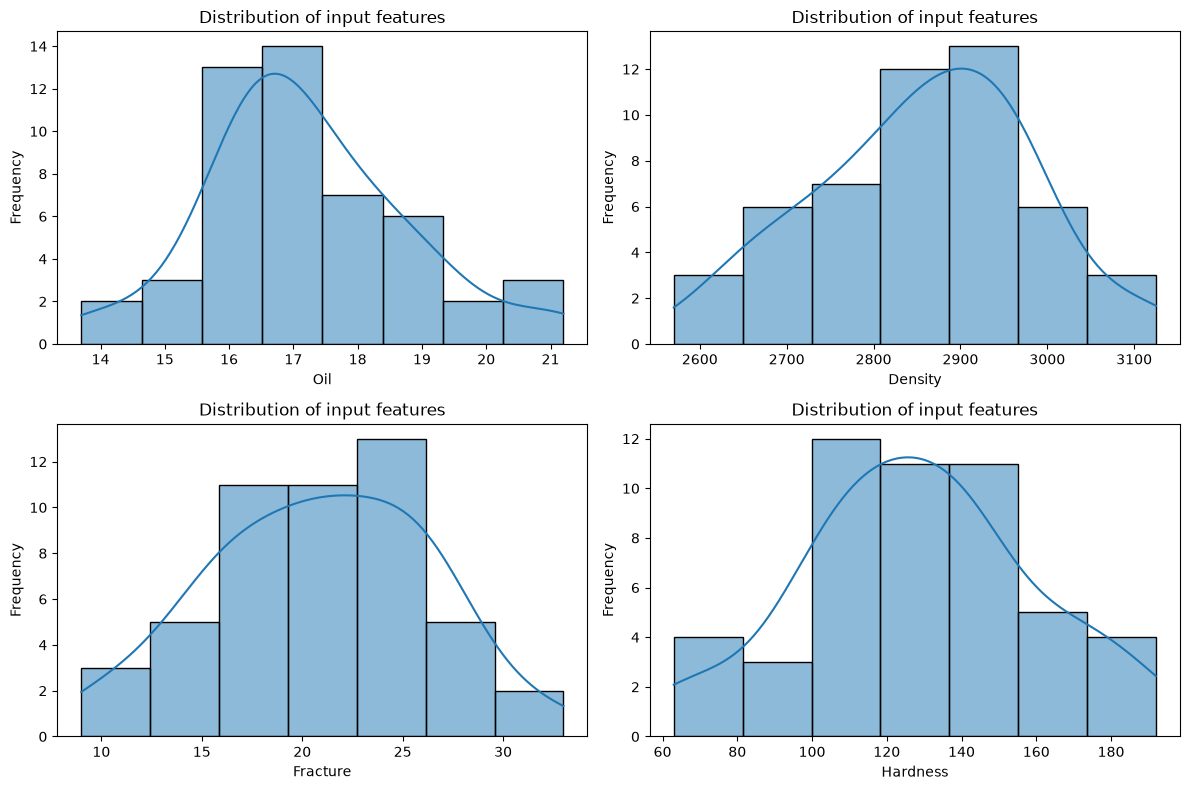

In [12]:
#Distribution plots

features = ["Oil","Density","Fracture","Hardness"]

plt.figure(figsize=(12,8))

for i, feature in enumerate(features):
    plt.subplot(2,2,i+1)
    
    sns.histplot(data=df, x=feature,kde=True)
    
    plt.title("Distribution of input features")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    
plt.tight_layout()
plt.show()

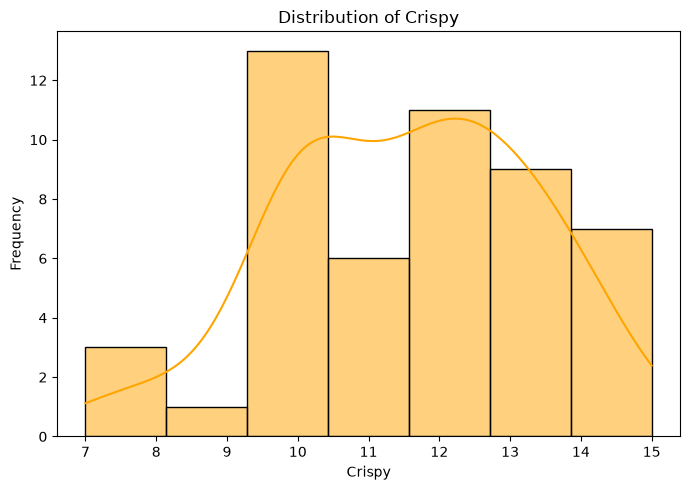

In [13]:
# DISTRIBUTION PLOT FOR TARGET: CRISPY

plt.figure(figsize=(7, 5))

sns.histplot(
    data=df,
    x="Crispy",
    kde=True,
    color="orange"
)

plt.title("Distribution of Crispy")
plt.xlabel("Crispy")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

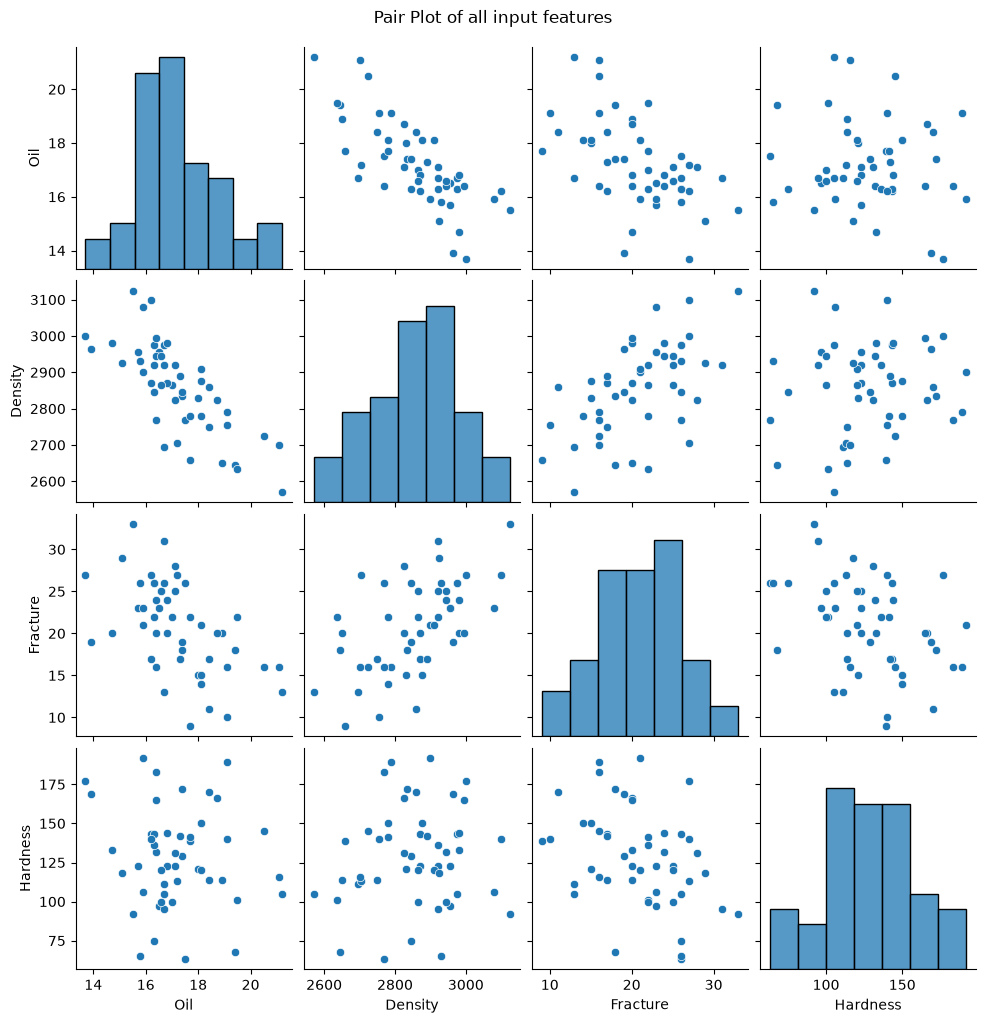

In [14]:
#pair plot for all input features

features = ["Oil","Density","Fracture","Hardness"]

sns.pairplot(df[features],diag_kind="hist")

plt.suptitle("Pair Plot of all input features",y=1.02)

plt.show()

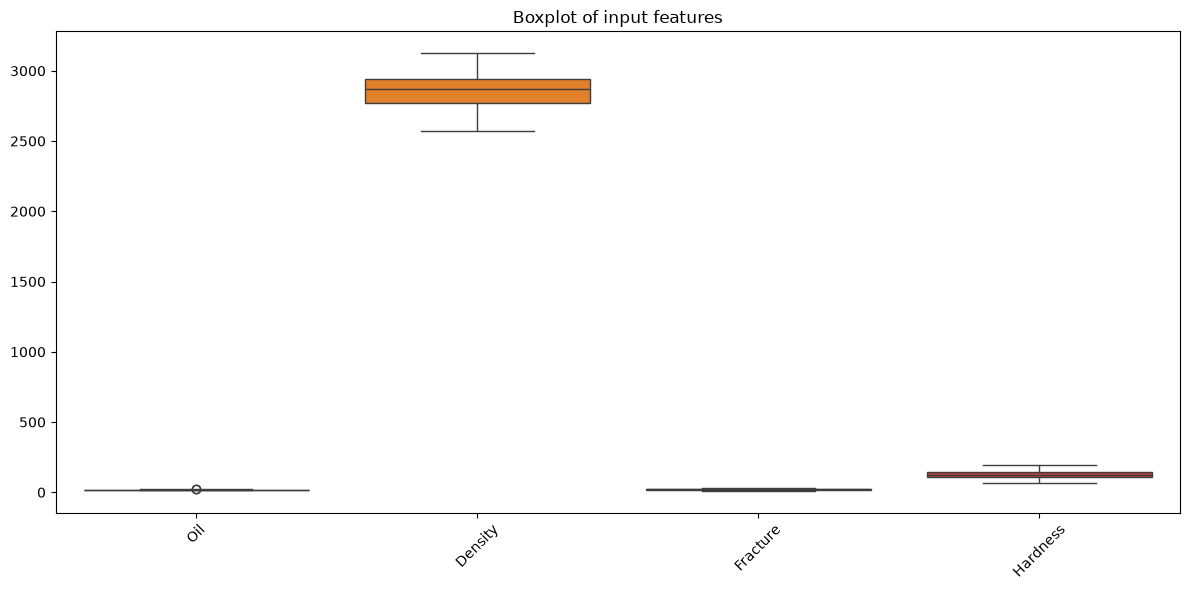

In [10]:
#Boxplots to identify outliers

plt.figure(figsize=(12,6))

sns.boxplot(data=X)

plt.title("Boxplot of input features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

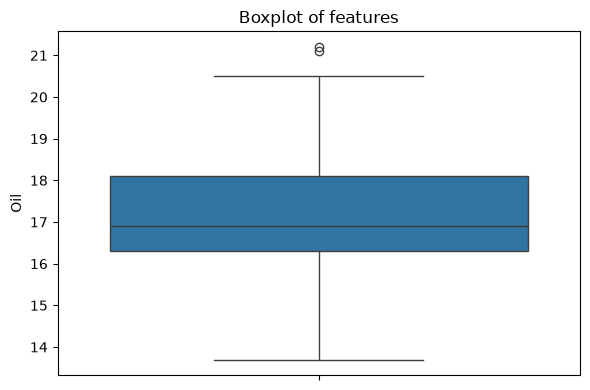

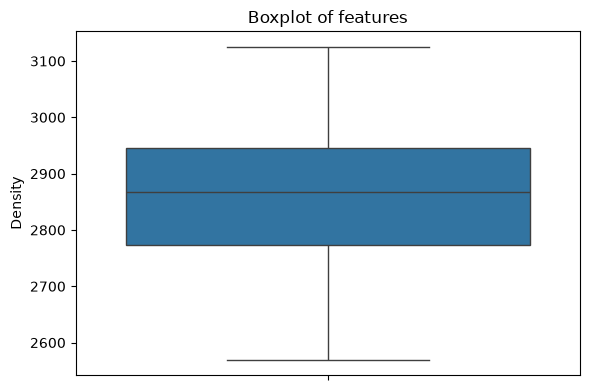

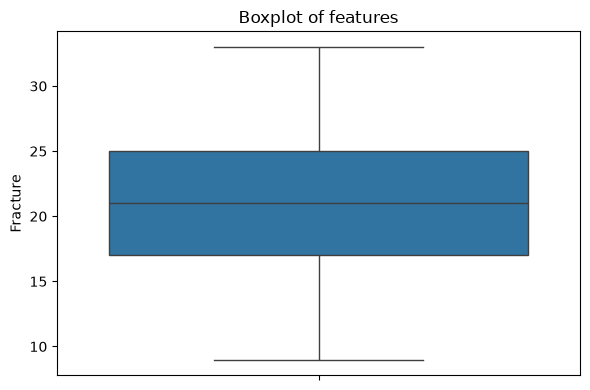

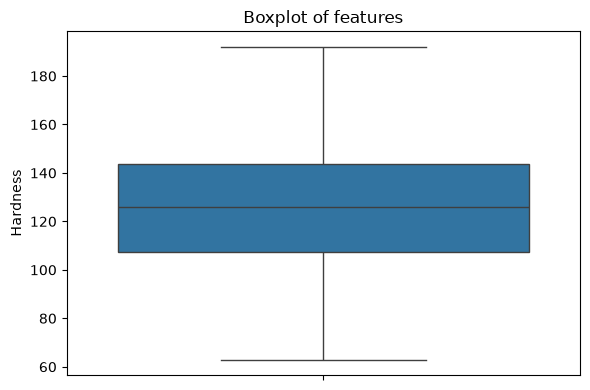

In [15]:
#Seperate boxplots for each input features

features = ["Oil","Density","Fracture","Hardness"]

for feature in features:
    plt.figure(figsize=(6,4))
    
    sns.boxplot(y=df[feature])
    
    plt.title("Boxplot of features")
    plt.ylabel(feature)
    
    plt.tight_layout()
    plt.show()

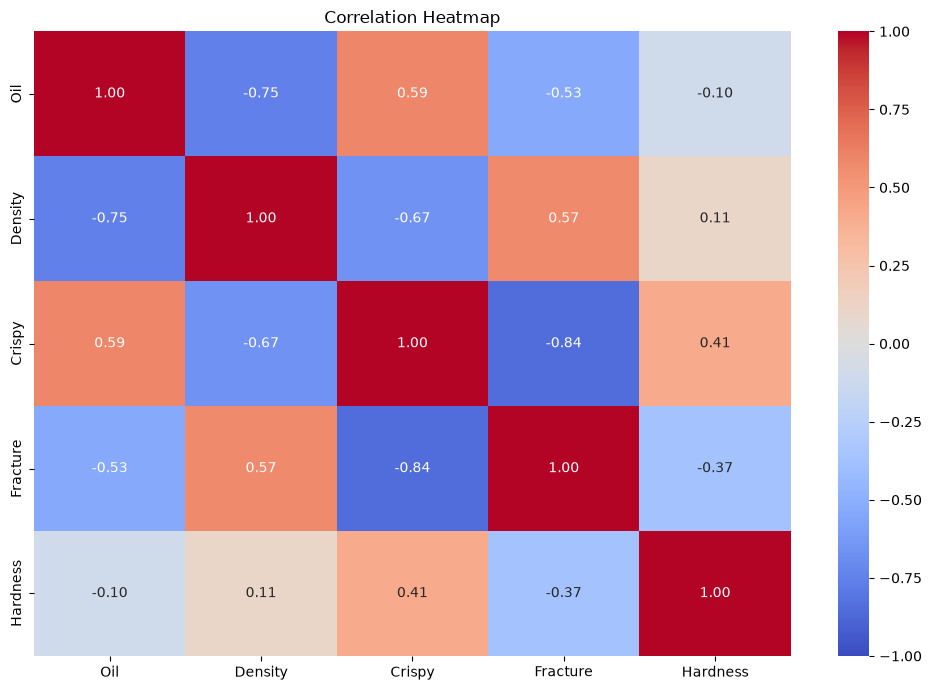

In [11]:
#Correlation heatmap

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10,7))

sns.heatmap(numeric_df.corr(),
            annot=True,
            cmap="coolwarm",
            fmt=".2f",
            vmin=-1,
            vmax=1)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [17]:
 #handle missing values

model_df = df.dropna(subset=["Crispy"]).copy()

for feature in features:
    if pd.api.types.is_numeric_dtype(model_df[feature]):
        model_df[feature] = model_df[feature].fillna(model_df[feature].median())
        
        
X = model_df[features]
y = model_df["Crispy"]

if not all(pd.api.types.is_numeric_dtype(X[col]) for col in features):
    raise ValueError(
        "All four input features must be numeric for this code."
    )


In [19]:
#Split data

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

print("training samples",len(X_train))
print("testing samples", len(X_test))

training samples 40
testing samples 10


In [ ]:
model = LinearRegression()

model.fit(X_train,y_train)

print("\n Linear regression model trained")

In [ ]:
y_pred = model.predict(X_test)

print("\n Actual vs Predicted Values")

results = pd.DataFrame({
    "Actual Crisy":y_test.values,
    "Predicted Crispy":y_
})